# Sentiment Pipeline — Women's E-Commerce Clothing Reviews

A clean TF-IDF + Logistic Regression pipeline for classifying clothing reviews as
**positive** or **negative**, with two variants:

- **Baseline** — standard TF-IDF features.
- **Contrast-aware** — the clause after a contrast marker ("but", "however",
  "although", ...) is duplicated before vectorizing, so "loved it, **but** it
  fell apart" is weighted toward the part that actually carries the sentiment.

This notebook is built specifically for the **Women's E-Commerce Clothing
Reviews** dataset (23,486 real reviews) — column names, the sentiment-label
rule, and the category/length/mixed-signal groupings below are all specific
to this dataset's fields, not a generic CSV loader.


## 1. Setup

In [1]:
import re
import numpy as np
import pandas as pd
import joblib

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 80)

## Plot style
Shared colours and defaults for every chart below (same palette as the pitch deck).

In [2]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

%matplotlib inline

# Palette shared with the pitch deck
BURGUNDY, NAVY, ROSE = "#6D2E46", "#2F3C7E", "#A26769"
RED, GREEN, INK, GREY, CREAM = "#B23A3A", "#3E7C59", "#2B2320", "#9B8F89", "#F7F1EC"
VARIANT_COLORS = {"baseline": NAVY, "contrast_aware": BURGUNDY}
CM_CMAP = LinearSegmentedColormap.from_list("deck", [CREAM, ROSE, BURGUNDY])
VARIANT_LABELS = {"baseline": "Baseline", "contrast_aware": "Contrast-aware"}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.edgecolor": GREY, "axes.labelcolor": INK, "axes.titlecolor": BURGUNDY,
    "axes.titleweight": "bold", "axes.titlesize": 11.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#E4D6CE", "grid.linewidth": 0.8, "axes.axisbelow": True,
})

## 2. Load the Women's E-Commerce Clothing Reviews dataset

Downloads the dataset (23,486 reviews, released by Nick Brooks) and derives every
column this pipeline needs directly from its known fields: `Review Text`,
`Rating`, and `Class Name`.


In [3]:
!wget -q "https://raw.githubusercontent.com/AFAgarap/ecommerce-reviews-analysis/master/Womens%20Clothing%20E-Commerce%20Reviews.csv" -O reviews.csv

df = pd.read_csv("reviews.csv", index_col=0)
df = df.rename(columns={"Review Text": "review_text", "Class Name": "category", "Rating": "rating"})
df = df.dropna(subset=["review_text"]).copy()

# Sentiment label: >=4 stars = positive, <=2 = negative, 3-star dropped as ambiguous
df = df[df["rating"] != 3].copy()
df["sentiment"] = (df["rating"] >= 4).astype(int)

# Collapse rare categories (<50 reviews) so audit slices stay meaningful
category_counts = df["category"].value_counts()
frequent_categories = category_counts[category_counts >= 50].index
df["category"] = df["category"].where(df["category"].isin(frequent_categories), "Other")
df["category"] = df["category"].fillna("Unlabeled")

# Review-length subgroup: split at the median word count
df["word_count"] = df["review_text"].str.split().str.len()
median_len = df["word_count"].median()
df["length_group"] = np.where(df["word_count"] <= median_len, "short", "detailed")

print(f"Reviews after cleaning: {len(df):,}")
print(f"Positive rate: {df['sentiment'].mean():.1%}")
print(f"Median review length: {median_len:.0f} words")
df[["review_text", "rating", "sentiment", "category", "length_group"]].head(3)

Reviews after cleaning: 19,818
Positive rate: 88.0%
Median review length: 58 words


,review_text,rating,sentiment,category,length_group
0,Absolutely wonderful - silky and sexy and comfortable,4,1,Intimates,short
1,"Love this dress! it's sooo pretty. i happened to find it in a store, and i...",5,1,Dresses,detailed
3,"I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time...",5,1,Pants,short


### 2b. Data overview — class balance, review length, category mix
Before modelling: the dataset is heavily skewed positive, which is why accuracy alone is
not enough and the audit sections below focus on **negative-review recall**.

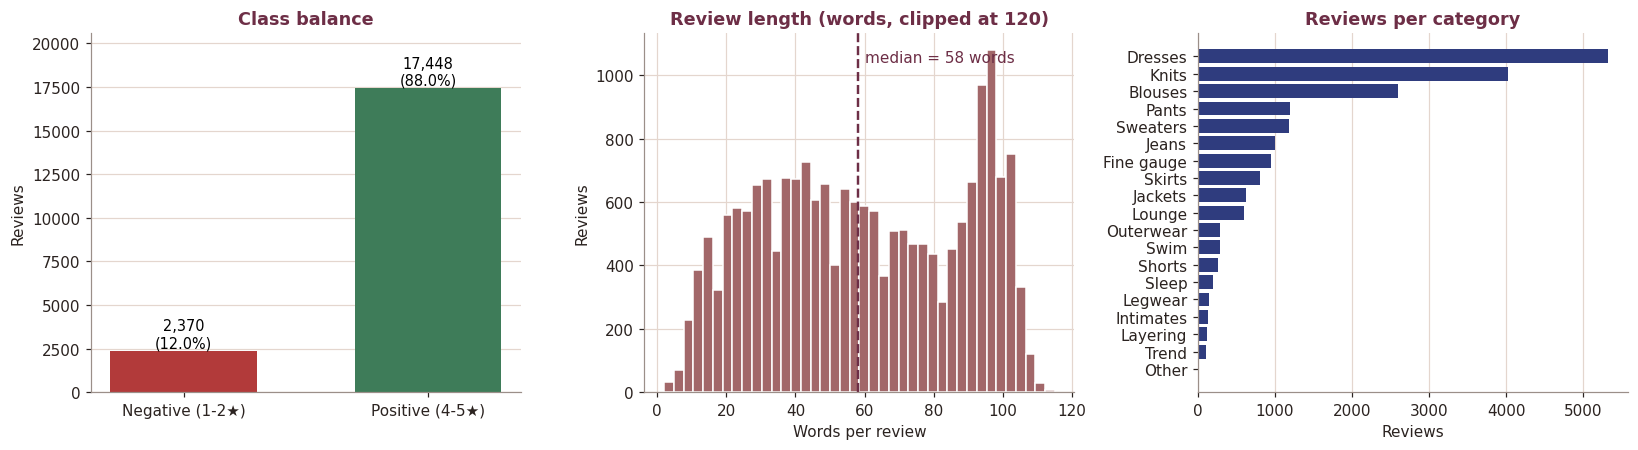

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# (a) class balance
counts = df["sentiment"].value_counts().sort_index()
bars = axes[0].bar(["Negative (1-2★)", "Positive (4-5★)"], counts.values, color=[RED, GREEN], width=0.6)
for b, v in zip(bars, counts.values):
    axes[0].text(b.get_x() + b.get_width() / 2, v, f"{v:,}\n({v / counts.sum():.1%})",
                 ha="center", va="bottom", fontsize=9.5)
axes[0].set_ylim(0, counts.max() * 1.18)
axes[0].set_title("Class balance"); axes[0].set_ylabel("Reviews"); axes[0].grid(axis="x", visible=False)

# (b) review length distribution
axes[1].hist(df["word_count"].clip(upper=120), bins=40, color=ROSE, edgecolor="white")
axes[1].axvline(median_len, color=BURGUNDY, ls="--", lw=1.6)
axes[1].text(median_len + 2, axes[1].get_ylim()[1] * 0.92, f"median = {median_len:.0f} words", color=BURGUNDY)
axes[1].set_title("Review length (words, clipped at 120)")
axes[1].set_xlabel("Words per review"); axes[1].set_ylabel("Reviews")

# (c) reviews per category
cat_counts = df["category"].value_counts().sort_values()
axes[2].barh(cat_counts.index, cat_counts.values, color=NAVY)
axes[2].set_title("Reviews per category"); axes[2].set_xlabel("Reviews"); axes[2].grid(axis="y", visible=False)

plt.tight_layout(); plt.show()

## 3. Text preprocessing

In [5]:
CONTRAST_MARKERS = ("but", "however", "although", "though", "unfortunately", "except", "yet")
_CONTRAST_RE = re.compile(r"\b(" + "|".join(CONTRAST_MARKERS) + r")\b", re.IGNORECASE)

def clean_text(text: str) -> str:
    """Lowercase, strip punctuation/digits, collapse whitespace."""
    text = text.lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def contrast_aware_text(raw_text: str) -> str:
    """Clean the text, then duplicate the clause after the first contrast
    marker so it carries roughly 2x TF-IDF weight."""
    cleaned = clean_text(raw_text)
    match = _CONTRAST_RE.search(raw_text)
    if not match:
        return cleaned
    trailing = clean_text(raw_text[match.end():])
    if len(trailing.split()) < 2:
        return cleaned
    return f"{cleaned} {trailing}"

# quick check
sample = "I loved the look, but after one wash it shrank terribly."
print("clean_text        :", clean_text(sample))
print("contrast_aware_text:", contrast_aware_text(sample))

clean_text        : i loved the look but after one wash it shrank terribly
contrast_aware_text: i loved the look but after one wash it shrank terribly after one wash it shrank terribly


## 4. The pipeline

One class, one flag (`contrast_aware`). Both variants share identical vectorizer
and model settings — the only difference is which text transform runs first —
so results are directly comparable.


In [6]:
class SentimentPipeline:
    def __init__(self, contrast_aware: bool = False, random_state: int = RANDOM_STATE):
        self.contrast_aware = contrast_aware
        self.vectorizer = TfidfVectorizer(
            stop_words=list(ENGLISH_STOP_WORDS), ngram_range=(1, 2),
            min_df=5, max_df=0.9, max_features=20000,
        )
        self.model = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=random_state)
        self.is_fitted = False

    def _transform(self, texts):
        fn = contrast_aware_text if self.contrast_aware else clean_text
        return [fn(t) for t in texts]

    def fit(self, texts, labels):
        X = self.vectorizer.fit_transform(self._transform(texts))
        self.model.fit(X, list(labels))
        self.is_fitted = True
        return self

    def predict(self, texts):
        X = self.vectorizer.transform(self._transform(texts))
        return self.model.predict(X)

    def predict_proba(self, texts):
        X = self.vectorizer.transform(self._transform(texts))
        return self.model.predict_proba(X)[:, 1]

    def evaluate(self, texts, labels):
        labels = np.asarray(list(labels))
        preds = self.predict(texts)
        accuracy = accuracy_score(labels, preds)
        precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average="binary")
        neg_mask = labels == 0
        negative_recall = (preds[neg_mask] == 0).mean() if neg_mask.any() else float("nan")
        return {
            "accuracy": accuracy, "precision": precision, "recall": recall,
            "f1": f1, "negative_recall": negative_recall,
            "confusion_matrix": confusion_matrix(labels, preds),
            "classification_report": classification_report(labels, preds, target_names=["negative", "positive"]),
        }

    def audit_by_group(self, texts, labels, groups, min_n=20):
        frame = pd.DataFrame({"text": list(texts), "label": list(labels), "group": list(groups)})
        frame["pred"] = self.predict(frame["text"])
        rows = []
        for group_value, subset in frame.groupby("group"):
            if len(subset) < min_n:
                continue
            negatives = subset[subset["label"] == 0]
            rows.append({
                "group": group_value, "n": len(subset),
                "accuracy": accuracy_score(subset["label"], subset["pred"]),
                "negative_recall": (negatives["pred"] == 0).mean() if len(negatives) else float("nan"),
            })
        return pd.DataFrame(rows).sort_values("negative_recall")

    def top_features(self, n=15):
        feature_names = np.array(self.vectorizer.get_feature_names_out())
        coefficients = self.model.coef_[0]
        top_pos_idx = np.argsort(coefficients)[-n:][::-1]
        top_neg_idx = np.argsort(coefficients)[:n]
        top_pos = pd.DataFrame({"feature": feature_names[top_pos_idx], "weight": coefficients[top_pos_idx]})
        top_neg = pd.DataFrame({"feature": feature_names[top_neg_idx], "weight": coefficients[top_neg_idx]})
        return top_pos, top_neg

    def explain(self, text, top_k=8):
        processed = self._transform([text])[0]
        vector = self.vectorizer.transform([processed])
        feature_names = np.array(self.vectorizer.get_feature_names_out())
        coefficients = self.model.coef_[0]
        nonzero_idx = vector.nonzero()[1]
        contributions = [
            {"term": feature_names[i], "weight": float(vector[0, i] * coefficients[i])}
            for i in nonzero_idx
        ]
        contributions.sort(key=lambda c: -abs(c["weight"]))
        return contributions[:top_k]

    def save(self, path):
        joblib.dump(self, path)

    @classmethod
    def load(cls, path):
        return joblib.load(path)

## 5. Train / test split

An 80/20 stratified split (by sentiment), kept identical for both model variants
so the comparison is fair.


In [7]:
train_df, test_df = train_test_split(
    df, test_size=0.2, random_state=RANDOM_STATE, stratify=df["sentiment"]
)
print(f"Train: {len(train_df):,}   Test: {len(test_df):,}")

Train: 15,854   Test: 3,964


## 6. Train and evaluate both variants

In [8]:
results = {}
for name, contrast_aware in [("baseline", False), ("contrast_aware", True)]:
    model = SentimentPipeline(contrast_aware=contrast_aware)
    model.fit(train_df["review_text"], train_df["sentiment"])
    metrics = model.evaluate(test_df["review_text"], test_df["sentiment"])
    results[name] = {"model": model, "metrics": metrics}

    print(f"\n=== {name} ===")
    print(f"Accuracy: {metrics['accuracy']:.3f}  Precision: {metrics['precision']:.3f}  "
          f"Recall: {metrics['recall']:.3f}  F1: {metrics['f1']:.3f}  "
          f"Negative recall: {metrics['negative_recall']:.3f}")


=== baseline ===
Accuracy: 0.915  Precision: 0.979  Recall: 0.923  F1: 0.950  Negative recall: 0.852



=== contrast_aware ===
Accuracy: 0.915  Precision: 0.979  Recall: 0.923  F1: 0.950  Negative recall: 0.857


In [9]:
print(results["baseline"]["metrics"]["classification_report"])

              precision    recall  f1-score   support

    negative       0.60      0.85      0.71       474
    positive       0.98      0.92      0.95      3490

    accuracy                           0.91      3964
   macro avg       0.79      0.89      0.83      3964
weighted avg       0.93      0.91      0.92      3964



### 6b. Model performance — baseline vs. contrast-aware
Both variants side by side on the held-out test set. Accuracy, precision, recall and F1 are
for the positive class; **negative recall** is the share of genuine complaints caught.

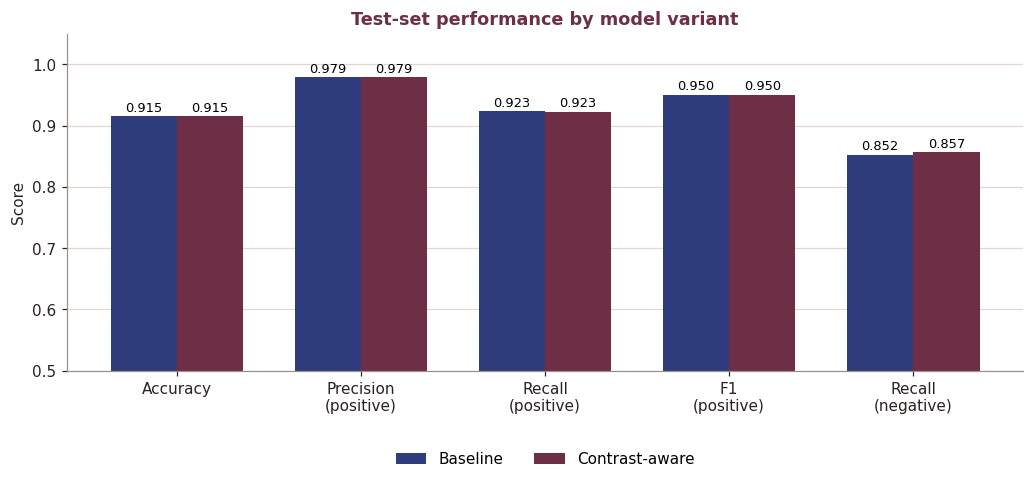

In [10]:
metric_keys = ["accuracy", "precision", "recall", "f1", "negative_recall"]
metric_names = ["Accuracy", "Precision\n(positive)", "Recall\n(positive)", "F1\n(positive)", "Recall\n(negative)"]
x = np.arange(len(metric_keys)); w = 0.36

fig, ax = plt.subplots(figsize=(9.5, 4.6))
for k, name in enumerate(["baseline", "contrast_aware"]):
    vals = [results[name]["metrics"][m] for m in metric_keys]
    bars = ax.bar(x + (k - 0.5) * w, vals, w, label=VARIANT_LABELS[name], color=VARIANT_COLORS[name])
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.008, f"{v:.3f}", ha="center", fontsize=8.5)
ax.set_xticks(x); ax.set_xticklabels(metric_names)
ax.set_ylim(0.5, 1.05); ax.set_ylabel("Score")
ax.set_title("Test-set performance by model variant")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.tight_layout(); plt.show()

### 6c. Confusion matrices
Counts in each cell, with the row-normalised rate underneath (e.g. the bottom-left cell
is the share of genuinely negative reviews that were correctly flagged as negative).

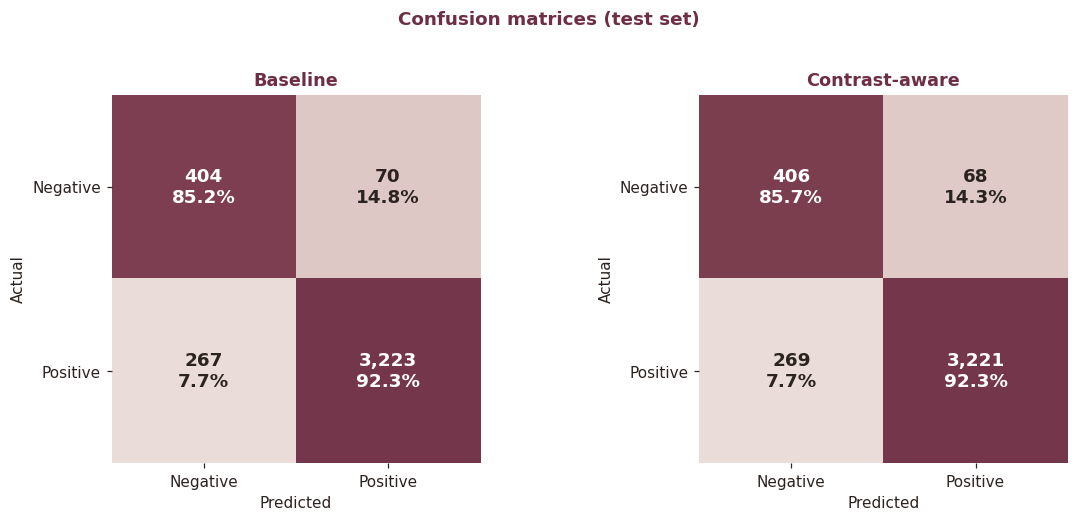

In [11]:
labels = ["Negative", "Positive"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, name in zip(axes, ["baseline", "contrast_aware"]):
    cmx = results[name]["metrics"]["confusion_matrix"]
    norm = cmx / cmx.sum(axis=1, keepdims=True)
    ax.imshow(norm, cmap=CM_CMAP, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cmx[i, j]:,}\n{norm[i, j]:.1%}", ha="center", va="center", fontsize=12,
                    color="white" if norm[i, j] > 0.55 else INK, fontweight="bold")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(labels); ax.set_yticklabels(labels)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title(VARIANT_LABELS[name]); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
plt.suptitle("Confusion matrices (test set)", color=BURGUNDY, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

### 6d. ROC and precision-recall curves
The precision-recall curve is the more honest view here because the classes are imbalanced (88 / 12).

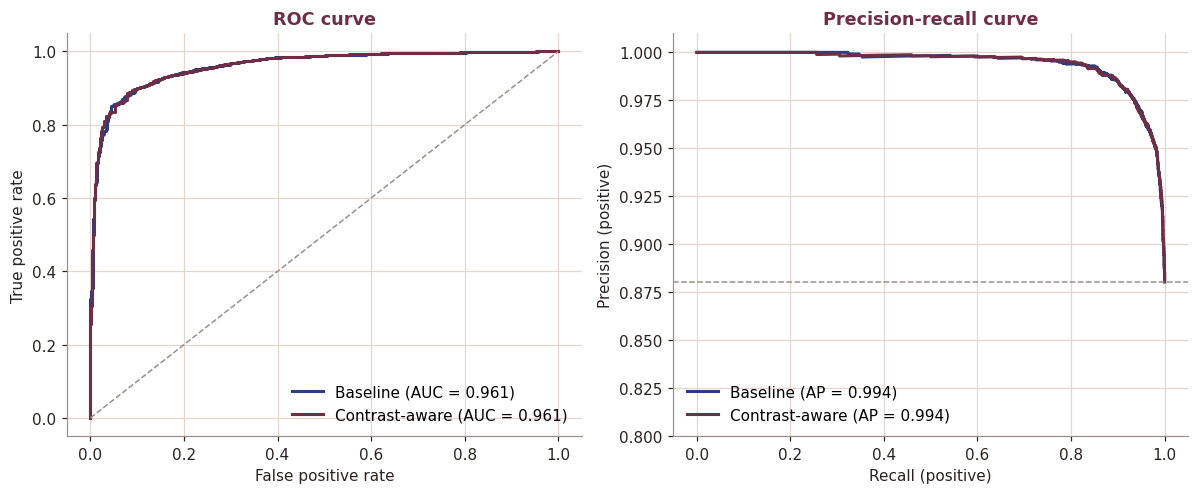

In [12]:
y_true = test_df["sentiment"].values
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for name in ["baseline", "contrast_aware"]:
    proba = results[name]["model"].predict_proba(test_df["review_text"])
    fpr, tpr, _ = roc_curve(y_true, proba)
    prec, rec, _ = precision_recall_curve(y_true, proba)
    axes[0].plot(fpr, tpr, color=VARIANT_COLORS[name], lw=2,
                 label=f"{VARIANT_LABELS[name]} (AUC = {auc(fpr, tpr):.3f})")
    axes[1].plot(rec, prec, color=VARIANT_COLORS[name], lw=2,
                 label=f"{VARIANT_LABELS[name]} (AP = {average_precision_score(y_true, proba):.3f})")
axes[0].plot([0, 1], [0, 1], color=GREY, ls="--", lw=1)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve")
axes[1].axhline(y_true.mean(), color=GREY, ls="--", lw=1)
axes[1].set(xlabel="Recall (positive)", ylabel="Precision (positive)", title="Precision-recall curve", ylim=(0.8, 1.01))
for ax in axes: ax.legend(frameon=False, loc="lower right" if ax is axes[0] else "lower left")
plt.tight_layout(); plt.show()

## 7. Audit — negative-review recall by product category

In [13]:
baseline_audit = results["baseline"]["model"].audit_by_group(
    test_df["review_text"], test_df["sentiment"], test_df["category"]
)
contrast_audit = results["contrast_aware"]["model"].audit_by_group(
    test_df["review_text"], test_df["sentiment"], test_df["category"]
)

comparison = baseline_audit.merge(
    contrast_audit, on=["group", "n"], suffixes=("_baseline", "_contrast_aware")
).sort_values("negative_recall_baseline")
comparison

,group,n,accuracy_baseline,negative_recall_baseline,accuracy_contrast_aware,negative_recall_contrast_aware
0,Intimates,26,0.884615,0.500000,0.884615,0.500000
1,Jeans,206,0.922330,0.538462,0.917476,0.538462
2,Pants,232,0.900862,0.636364,0.900862,0.681818
3,Skirts,145,0.917241,0.785714,0.924138,0.785714
4,Lounge,115,0.930435,0.800000,0.930435,0.800000
5,Swim,59,0.881356,0.818182,0.898305,0.818182
6,Blouses,478,0.899582,0.847458,0.914226,0.864407
7,Jackets,113,0.911504,0.857143,0.911504,0.857143
8,Fine gauge,198,0.949495,0.857143,0.924242,0.857143
9,Dresses,1109,0.906222,0.859060,0.908025,0.879195


### 7b. Negative-review recall by category (chart)
Categories with at least 100 test reviews are shown; smaller categories (e.g. Intimates, with
only a couple of negative test reviews) are too noisy to plot reliably.

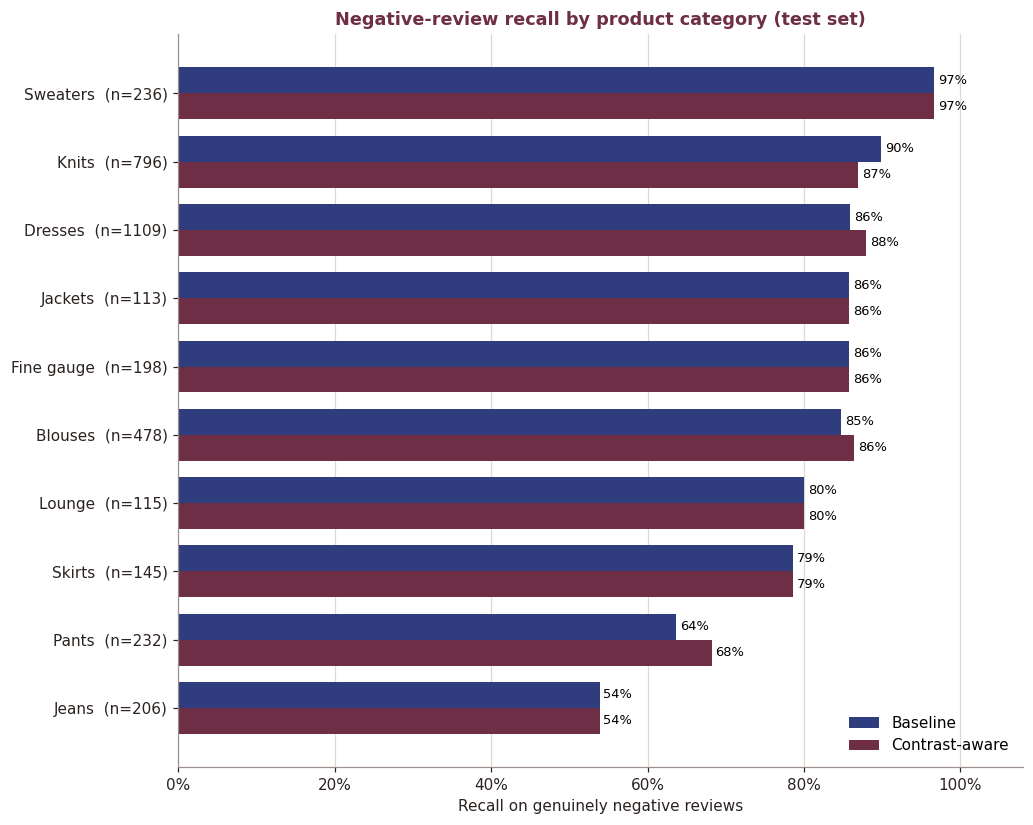

In [14]:
plot_df = comparison[comparison["n"] >= 100].sort_values("negative_recall_baseline", ascending=False)
y = np.arange(len(plot_df)); h = 0.38

fig, ax = plt.subplots(figsize=(9.5, 0.6 * len(plot_df) + 1.6))
for k, (col, name) in enumerate([("negative_recall_baseline", "baseline"),
                                 ("negative_recall_contrast_aware", "contrast_aware")]):
    bars = ax.barh(y + (k - 0.5) * h, plot_df[col], h, color=VARIANT_COLORS[name], label=VARIANT_LABELS[name])
    for b, v in zip(bars, plot_df[col]):
        ax.text(v + 0.005, b.get_y() + b.get_height() / 2, f"{v:.0%}", va="center", fontsize=8.5)
ax.set_yticks(y); ax.set_yticklabels([f"{g}  (n={n})" for g, n in zip(plot_df["group"], plot_df["n"])])
ax.invert_yaxis(); ax.set_xlim(0, 1.08); ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel("Recall on genuinely negative reviews")
ax.set_title("Negative-review recall by product category (test set)")
ax.grid(axis="y", visible=False); ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

**Finding:** negative-review recall varies widely across categories (Jeans and
Pants are consistently the weakest) even though overall accuracy looks similar
everywhere. The contrast-aware variant nudges some categories upward without
fully closing the gap.

## 8. Audit — short vs. detailed reviews

In [15]:
length_rows = []
for name, r in results.items():
    for grp, sub in test_df.groupby("length_group"):
        m = r["model"]
        preds = m.predict(sub["review_text"])
        neg = sub[sub["sentiment"] == 0]
        neg_recall = (preds[sub["sentiment"].values == 0] == 0).mean() if len(neg) else float("nan")
        length_rows.append({"model": name, "length_group": grp, "n": len(sub),
                             "accuracy": accuracy_score(sub["sentiment"], preds),
                             "negative_recall": neg_recall})
length_df = pd.DataFrame(length_rows)
length_df

,model,length_group,n,accuracy,negative_recall
0,baseline,detailed,1911,0.905808,0.848739
1,baseline,short,2053,0.923527,0.855932
2,contrast_aware,detailed,1911,0.902669,0.840336
3,contrast_aware,short,2053,0.926449,0.872881


### 8b. Short vs. detailed reviews (chart)

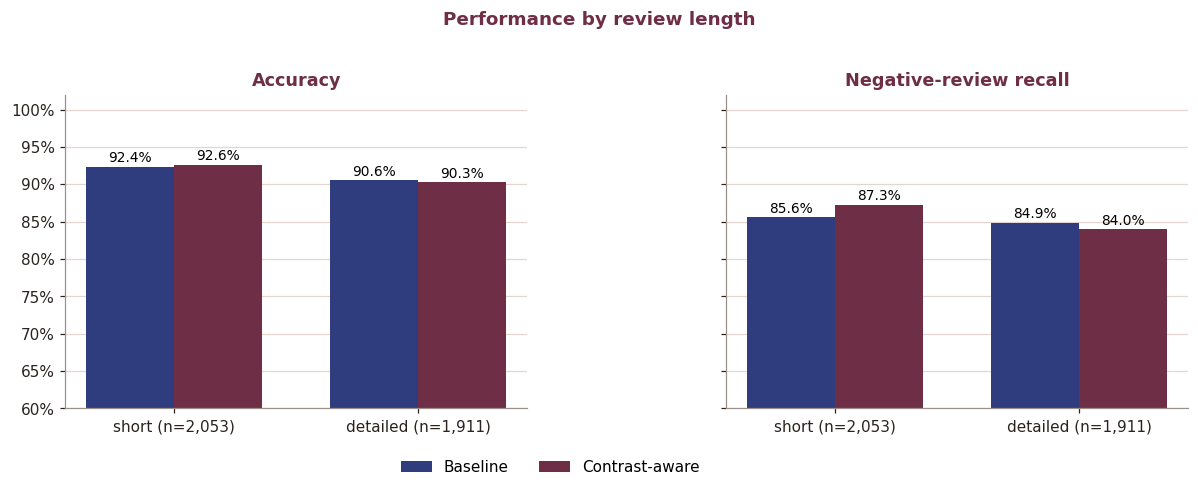

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
groups = ["short", "detailed"]; x = np.arange(2); w = 0.36
for ax, metric, title in zip(axes, ["accuracy", "negative_recall"], ["Accuracy", "Negative-review recall"]):
    for k, name in enumerate(["baseline", "contrast_aware"]):
        vals = [length_df[(length_df["model"] == name) & (length_df["length_group"] == g)][metric].iloc[0] for g in groups]
        bars = ax.bar(x + (k - 0.5) * w, vals, w, color=VARIANT_COLORS[name], label=VARIANT_LABELS[name])
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.006, f"{v:.1%}", ha="center", fontsize=9)
    ns = length_df.drop_duplicates("length_group").set_index("length_group")["n"]
    ax.set_xticks(x); ax.set_xticklabels([f"{g} (n={ns[g]:,})" for g in groups])
    ax.set_title(title); ax.set_ylim(0.6, 1.02); ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False, loc="upper center", bbox_to_anchor=(1.05, -0.12), ncol=2)
plt.suptitle("Performance by review length", color=BURGUNDY, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

**Finding:** short and detailed reviews perform within a couple of points of
each other for both variants — review length is not where this pipeline's bias
lives, unlike product category.

## 9. Explainability

In [17]:
top_pos, top_neg = results["contrast_aware"]["model"].top_features(n=10)
print("Top positive features:"); print(top_pos.to_string(index=False))
print("\nTop negative features:"); print(top_neg.to_string(index=False))

Top positive features:
    feature   weight
       love 7.436635
    perfect 6.104517
     little 5.960000
comfortable 5.869444
      great 5.420677
       fits 4.209940
       soft 4.162706
        bit 3.751961
  perfectly 3.594635
      happy 3.583478

Top negative features:
     feature    weight
disappointed -7.042041
       cheap -5.007821
    returned -4.862537
 wanted love -4.816297
unflattering -4.718319
        huge -4.512736
   returning -4.366208
      return -4.342558
      fabric -4.148873
         way -4.140385


### 9b. Top features (chart)
Largest logistic-regression weights per variant. Positive weights push toward *positive*
sentiment, negative weights toward *negative*.

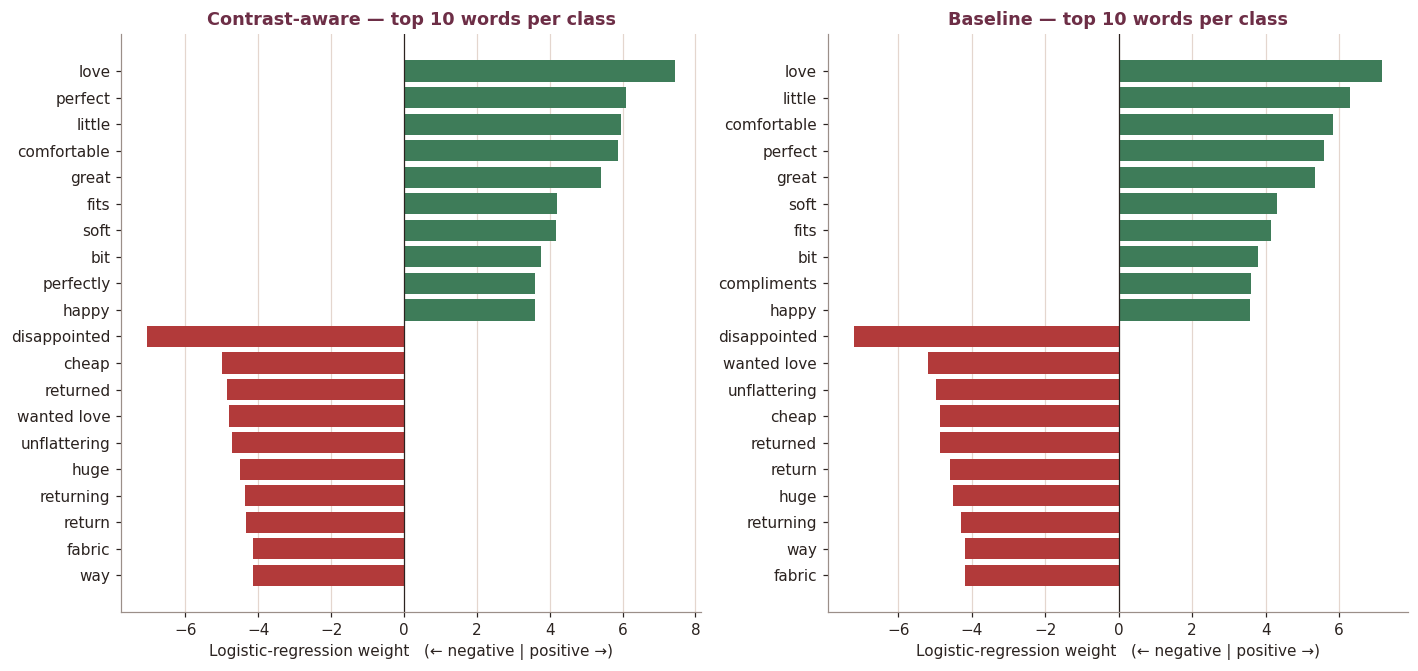

In [18]:
def plot_top_features(ax, model, title, n=10):
    pos, neg = model.top_features(n=n)
    frame = pd.concat([pos.sort_values("weight", ascending=False), neg.sort_values("weight")])
    colors = [GREEN if w > 0 else RED for w in frame["weight"]]
    ax.barh(frame["feature"], frame["weight"], color=colors)
    ax.axvline(0, color=INK, lw=0.8); ax.invert_yaxis()
    ax.set_title(title); ax.set_xlabel("Logistic-regression weight   (← negative | positive →)")
    ax.grid(axis="y", visible=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 6.2))
plot_top_features(axes[0], results["contrast_aware"]["model"], "Contrast-aware — top 10 words per class")
plot_top_features(axes[1], results["baseline"]["model"], "Baseline — top 10 words per class")
plt.tight_layout(); plt.show()

In [19]:
sample_review = "I loved the look and the fit was great, but after one wash it shrank terribly."
model = results["contrast_aware"]["model"]
pred = model.predict([sample_review])[0]
proba = model.predict_proba([sample_review])[0]
print(f"Review: {sample_review}")
print(f"Prediction: {'positive' if pred == 1 else 'negative'}  (p_positive={proba:.3f})\n")
print("Top contributing words:")
for c in model.explain(sample_review, top_k=6):
    print(f"  {c['term']:<20} {c['weight']:+.3f}")

Review: I loved the look and the fit was great, but after one wash it shrank terribly.
Prediction: negative  (p_positive=0.238)

Top contributing words:
  shrank               -0.672
  terribly             -0.518
  great                +0.486
  wash                 -0.450
  loved look           -0.210
  fit                  +0.085


### 9c. Why did the model call this review negative? (chart)

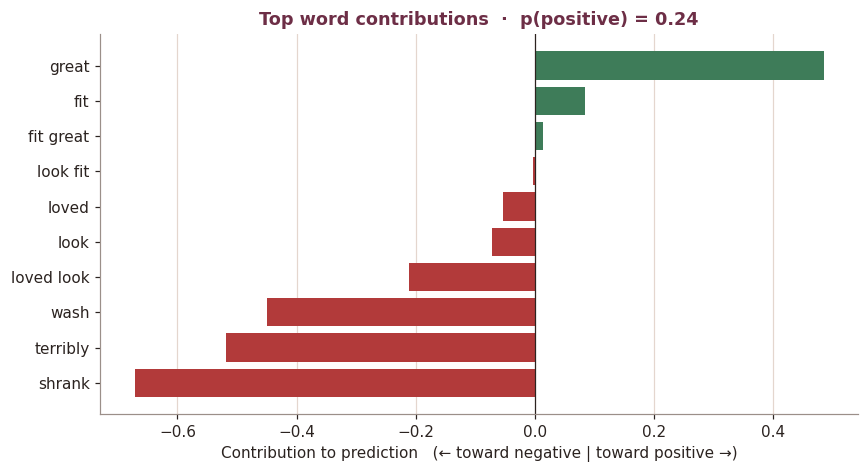

In [20]:
contribs = model.explain(sample_review, top_k=10)
contribs = sorted(contribs, key=lambda c: c["weight"])
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh([c["term"] for c in contribs], [c["weight"] for c in contribs],
        color=[GREEN if c["weight"] > 0 else RED for c in contribs])
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlabel("Contribution to prediction   (← toward negative | toward positive →)")
ax.set_title(f"Top word contributions  ·  p(positive) = {proba:.2f}")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Reading it:** despite the review opening with genuine praise ("loved",
"great"), the contrast-aware model correctly reads "shrank" and "terribly" —
the words after "but" — as the dominant signal, and classifies it negative.

## 10. Save both trained models

In [21]:
results["baseline"]["model"].save("baseline_model.joblib")
results["contrast_aware"]["model"].save("contrast_aware_model.joblib")
print("Saved baseline_model.joblib and contrast_aware_model.joblib")

Saved baseline_model.joblib and contrast_aware_model.joblib


## 11. Summary

- **Baseline (TF-IDF + Logistic Regression):** 91.5% accuracy, 85.2% negative-review recall.
- **Contrast-aware variant:** same 91.5% accuracy, improves negative-review recall to 85.7%,
  with the biggest gains on reviews that open with praise and pivot on "but"/"however".
- **Category audit:** Jeans and Pants remain the weakest categories under both variants —
  a data/vocabulary issue this pipeline surfaces but does not fully solve.
- **Length audit:** short vs. detailed reviews perform comparably — not a bias driver here.
